# Compare reconstruction quality
Select your own compatible checkpoints/exports. All methods use one immutable validation plan,64×64 spatial queries and the declared physical times; wave u/v remain separate. No training or test-split model selection runs. With no neural checkpoint selected, the safe default evaluates **D only**. It never substitutes old smoke models.

In [1]:
from pathlib import Path
import sys, subprocess, importlib.util
PROJECT_DIR = None  # Colab: "/content/PDEep" after uploading/cloning the complete project.
INSTALL_PROJECT = False  # Colab first use: True. Local editable install: False.
if PROJECT_DIR is not None:
    project = Path(PROJECT_DIR).expanduser().resolve()
    if not (project / "pyproject.toml").is_file():
        raise RuntimeError("PROJECT_DIR must contain the complete PDEep project")
    if INSTALL_PROJECT:
        subprocess.run([sys.executable, "-m", "pip", "install", "-e", str(project)], check=True)
import pdeep, json
ROOT = Path(pdeep.__file__).resolve().parents[2]
if PROJECT_DIR is not None and ROOT != project:
    raise RuntimeError("Kernel imports another PDEep checkout; install this project and restart the kernel")
from IPython.display import display, Markdown
from pdeep.notebook_workflows import initialize
print("Project:", ROOT)


Project: /Users/nicolasackermann/Documents/ChatGPT/PDEep


In [2]:
CHECKPOINTS = {}  # e.g. {"B0":"/path/to/B0/export.json", "B1":"/path/to/B1/export.json"}
PDE_FAMILIES = ("poisson", "heat", "wave")
DEVICE = "auto"
ALLOW_PARTIAL = False  # explicit opt-in for smoke/bounded/unfinished research runs
CASE_IDS = (0,)  # tiny fixed validation subset; not the untouched test split
PLAN_PATH = None  # optional independently saved matched EvaluationPlan JSON
OBSERVATION_DIAGNOSTICS = False  # optional controlled sensor perturbations
SHOW_EXECUTION_CHECKPOINTS = False  # catalog only; never auto-selects models


In [3]:
from pdeep.notebook_workflows import load_evaluation_selection,checkpoint_catalog
CONTEXT=initialize(ROOT,device=DEVICE)
print(CONTEXT.device_message)
CATALOG=checkpoint_catalog(ROOT,include_partial=SHOW_EXECUTION_CHECKPOINTS)
print("Available explicit candidates:",CATALOG or "No completed research checkpoint found. Train one in 02_train.ipynb; D is available now.")
METHODS=load_evaluation_selection(CONTEXT,CHECKPOINTS,allow_partial=ALLOW_PARTIAL)
for method in METHODS:
    print(method.name,"| status",method.status,"| successful updates",method.training.get("successful_updates",0),"|",method.checkpoint)


DEVICE='auto' selected mps/float32: first available: CUDA, MPS, CPU. References and B/D physics stay CPU float64. No runtime fallback.
Available explicit candidates: No completed research checkpoint found. Train one in 02_train.ipynb; D is available now.


D | status exact; no training | successful updates 0 | exact-T1-Gaussian


## One common evaluation plan
The plan fixes cases, conditioning/independent held-out sensors, geometry, physical times, quantities, normalization and metric reductions for every selected method. Reusing a plan requires matching its PDE/diagnostic settings. D's point estimate is its posterior mean; deterministic neural uncertainty is unavailable.

In [4]:
from pdeep.notebook_workflows import make_evaluation_plan,evaluate_selected
PLAN,EVALUATION_CONFIG=make_evaluation_plan(CONTEXT,pdes=PDE_FAMILIES,case_ids=CASE_IDS,plan_path=PLAN_PATH,observation_diagnostics=OBSERVATION_DIAGNOSTICS)
print("Plan",PLAN.identity,"| split",PLAN.split,"| cases",[c.physical_id for c in PLAN.cases])
print("Stationary physical time absent; dynamic times:",PLAN.dynamic_times)


Plan 580f92b5bf3acb2ed1057f1103b36493c0ca2300ae402f56c270b38c1ef5af99 | split validation | cases ['poisson/12000', 'heat/12000', 'wave/12000']
Stationary physical time absent; dynamic times: (0.0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0)


In [5]:
RESULT=evaluate_selected(CONTEXT,METHODS,PLAN,EVALUATION_CONFIG)
from pdeep.evaluation_plotting import comparison_table
display(Markdown(comparison_table(RESULT)))
print("All quantity/PDE metrics and physical-case aggregation are preserved in JSON.")


| Method | Status | Updates | Macro standardized MSE | Median full inference, ms |
|---|---|---:|---:|---:|
| D | exact; no training | 0 | 0.000352154 | 33.930 |

All quantity/PDE metrics and physical-case aggregation are preserved in JSON.


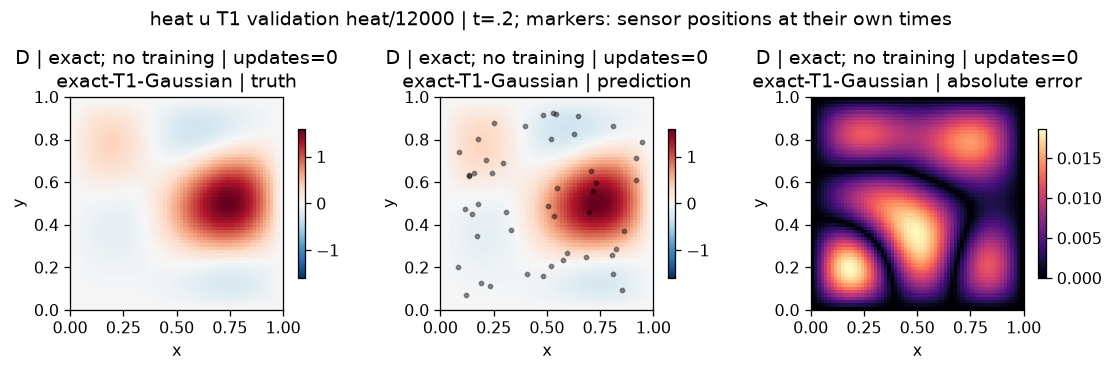

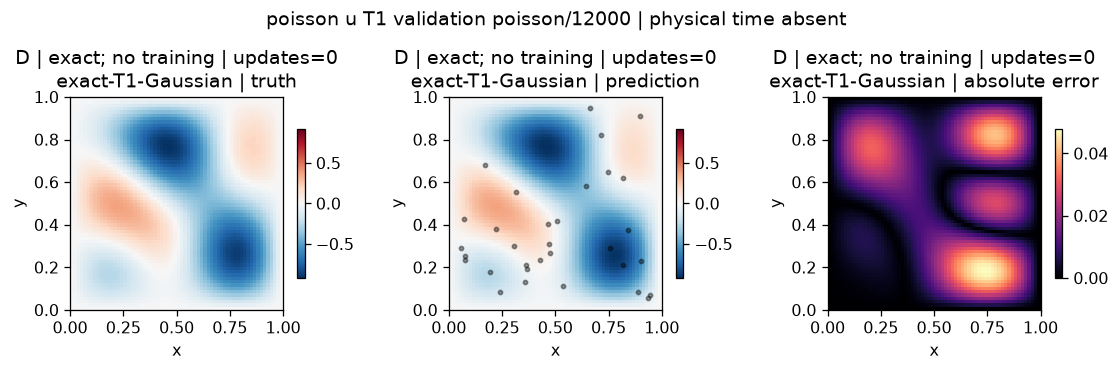

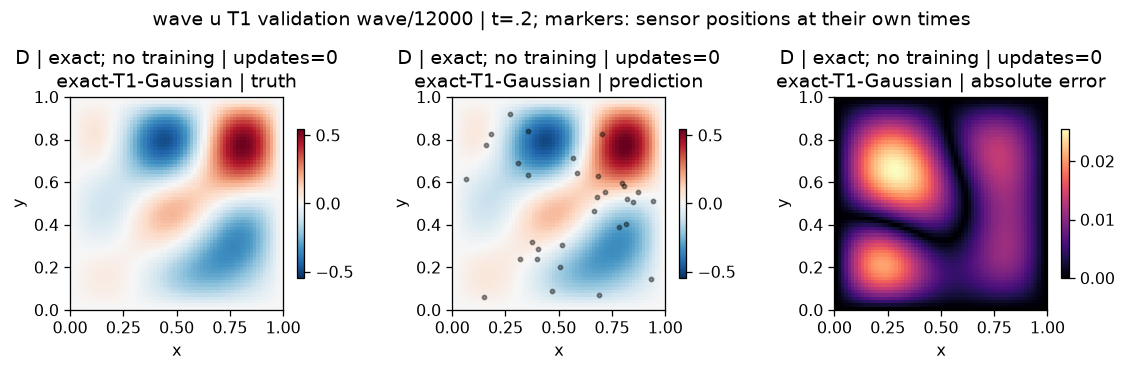

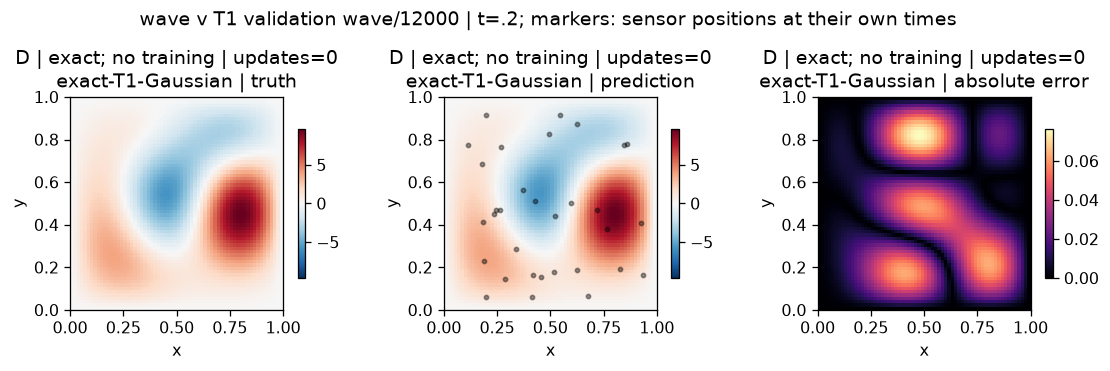

In [6]:
from pdeep.workflow_plotting import plot_evaluation
PLOTS=plot_evaluation(RESULT)
from IPython.display import Image
for path in PLOTS:
    if path.name.startswith("fields_"):display(Image(filename=str(path),width=1000))


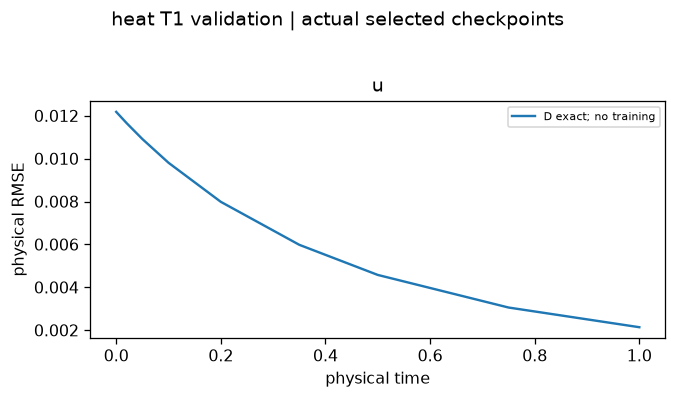

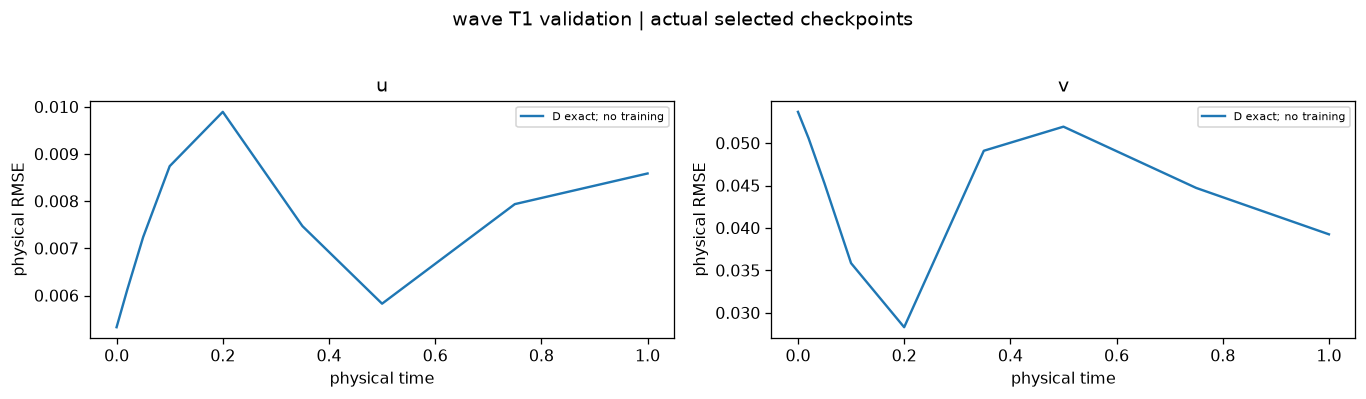

B0/B1 are separate models. A disabled pathway or larger parameter count is not evidence of superiority.


In [7]:
for path in PLOTS:
    if path.name.startswith(("time_","B_refinement")):display(Image(filename=str(path),width=1000))
print("B0/B1 are separate models. A disabled pathway or larger parameter count is not evidence of superiority.")


In [8]:
for name,rows in RESULT["scientific"]["cases"].items():
    for row in rows:
        physics=row.get("physics",{})
        print(name,row["pde"],"strong physical RMSE:",physics.get("physical_RMSE"),"boundary:",physics.get("boundary_max_abs"))
        if "C_separate_weak_diagnostics" in physics:print("C weak residual (separate):",physics["C_separate_weak_diagnostics"])
print("Strong residuals use independent interior points; reconstruction errors remain separate from representational consistency.")


D poisson strong physical RMSE: [5.48227072846001e-15] boundary: {'u': 2.620505996857478e-16}
D heat strong physical RMSE: [6.204946277280139e-17] boundary: {'u': 5.53530082359046e-16}
D wave strong physical RMSE: [5.501161622130799e-16, 4.4740748172089364e-15] boundary: {'u': 4.4327651740236955e-16, 'v': 2.0821561010402186e-15}
Strong residuals use independent interior points; reconstruction errors remain separate from representational consistency.


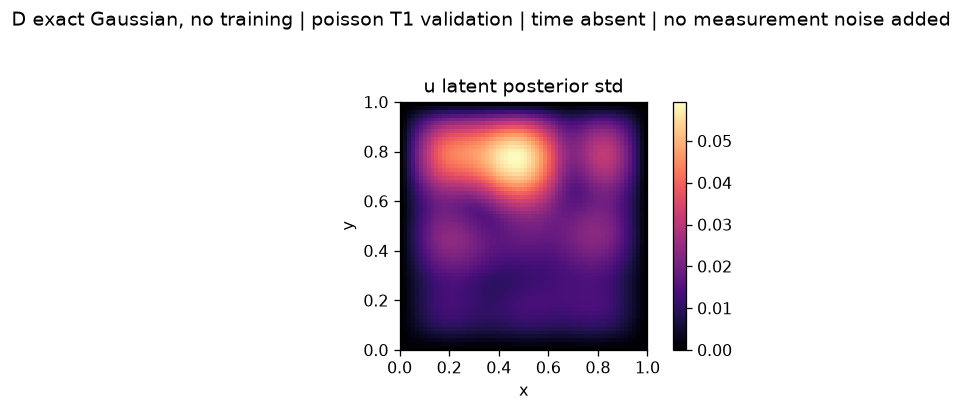

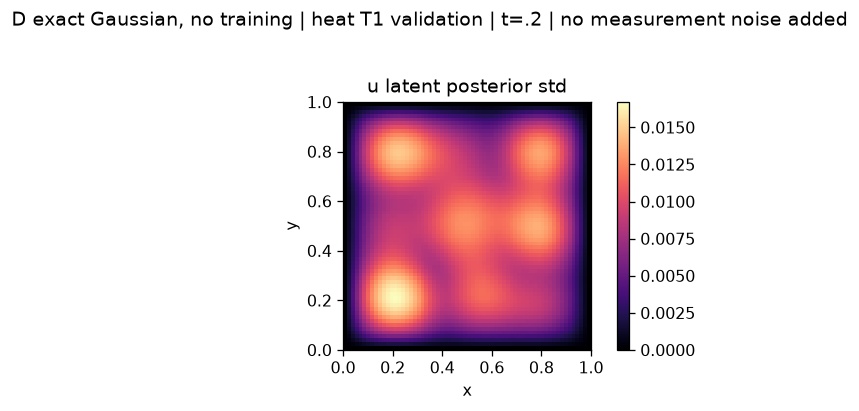

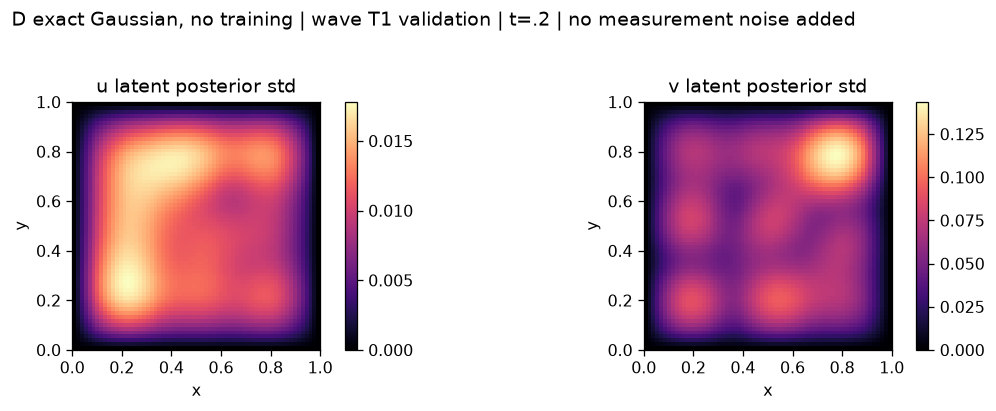

D: exact latent posterior variance and independent held-out predictive scores. Neural posterior uncertainty: unavailable.
D coverage intervals: {'coefficient_coverage': {'0.5': {'estimate': 0.48148148148148145, 'CI95': [0, 1], 'method': 'bounded independent physical-case Hoeffding; no pointwise independence assumption'}, '0.9': {'estimate': 1.0, 'CI95': [0.21589972430031457, 1], 'method': 'bounded independent physical-case Hoeffding; no pointwise independence assumption'}, '0.95': {'estimate': 1.0, 'CI95': [0.21589972430031457, 1], 'method': 'bounded independent physical-case Hoeffding; no pointwise independence assumption'}}, 'heldout_latent_coverage': {'0.5': {'estimate': 0.4965277777777778, 'CI95': [0, 1], 'method': 'bounded independent physical-case Hoeffding; no pointwise independence assumption'}, '0.9': {'estimate': 0.9114583333333333, 'CI95': [0.12735805763364783, 1], 'method': 'bounded independent physical-case Hoeffding; no pointwise independence assumption'}, '0.95': {'estim

In [9]:
for path in PLOTS:
    if path.name.startswith("D_uncertainty_"):display(Image(filename=str(path),width=1000))
print("D: exact latent posterior variance and independent held-out predictive scores. Neural posterior uncertainty: unavailable.")
print("D coverage intervals:",RESULT["scientific"]["D_coverage_intervals"])


In [10]:
print("Exported JSON, fields and figures:",RESULT["directory"])
print("Plan:",PLAN.identity,"| scientific result:",RESULT["identity"])
print("Run metadata:",{name:{"status":r["training_status"],"updates":r["training_selection"]["successful_updates"]} for name,r in RESULT["scientific"]["methods"].items()})
print("No optimizer updates; no neural uncertainty invented; no test-set selection.")


Exported JSON, fields and figures: /Users/nicolasackermann/Documents/ChatGPT/PDEep/reports/evaluation_runs/notebook-c34c402c83cb/580f92b5bf3acb2ed1057f1103b36493c0ca2300ae402f56c270b38c1ef5af99
Plan: 580f92b5bf3acb2ed1057f1103b36493c0ca2300ae402f56c270b38c1ef5af99 | scientific result: 1a072caf9d60f1cfa5bb27d256ae8982d41e753370c2a8a9e60c30fe511026b5
Run metadata: {'D': {'status': 'exact; no training', 'updates': None}}
No optimizer updates; no neural uncertainty invented; no test-set selection.


To compare **B0 and B1**, train/select each independently in02, then put both inference-export paths in `CHECKPOINTS`. Defaults require completed research models. To inspect execution-only artifacts, explicitly set `ALLOW_PARTIAL=True`; their status and completed-update count stay visible. Missing paths or incompatible normalization/architectures fail rather than substituting another experiment. Multiple independent seeds and larger physical-case subsets are needed for serious scientific comparisons.